# Google Play Store – App Type and Rating Classification

***Targets:***

*   **Task 1:** Check whether an app is Free or Paid. If Free → print *Free*. If Paid → predict its price.

*   **Task 2:** Predict app rating. If rating > 4.5 → *Recommended*, else → *Not Recommended*.

Models: Logistic Regression, Linear Regression, Decision Tree, Random Forest, XGBoost, KNN, Voting Classifier/Regressor

In [1]:
#importing the necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, VotingClassifier, VotingRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, classification_report,
                              precision_score, recall_score, f1_score,
                              mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

# ignore the warning messages
import warnings
warnings.filterwarnings('ignore')

# Exploratory Data Analysis (EDA)

***Google Play Store Dataset:***

*   **App** - Name of the application

*   **Category** - Category the app belongs to (e.g., GAME, TOOLS, FINANCE)

*   **Rating** - Average user rating of the app (out of 5.0)

*   **Reviews** - Number of user reviews

*   **Size** - Size of the app (in MB or kB)

*   **Installs** - Number of times the app has been installed

*   **Type** - Whether the app is Free or Paid *(Target for Task 1a)*

*   **Price** - Price of the app in USD. 0 for free apps *(Target for Task 1b)*

*   **Content Rating** - Age group the app is targeted at (e.g., Everyone, Teen, Mature 17+)

*   **Genres** - Genre(s) of the app

*   **Last Updated** - Date the app was last updated

*   **Current Ver** - Current version of the app

*   **Android Ver** - Minimum Android version required

In [2]:
# load the dataset (Kaggle: Google Play Store Apps)
df = pd.read_csv('data/googleplaystore.csv')

# let's look at the first few instances
df.head(10)

,Unnamed: 0,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,7-Jan-18,1.0.0,4.0.3 and up
1,1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15-Jan-18,2.0.0,4.0.3 and up
2,2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,1-Aug-18,1.2.4,4.0.3 and up
3,3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,8-Jun-18,Varies with device,4.2 and up
4,4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,20-Jun-18,1.1,4.4 and up
5,5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,"50,000+",Free,0,Everyone,Art & Design,26-Mar-17,1,2.3 and up
6,6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19M,"50,000+",Free,0,Everyone,Art & Design,26-Apr-18,1.1,4.0.3 and up
7,7,Infinite Painter,ART_AND_DESIGN,4.1,36815,29M,"1,000,000+",Free,0,Everyone,Art & Design,14-Jun-18,6.1.61.1,4.2 and up
8,8,Garden Coloring Book,ART_AND_DESIGN,4.4,13791,33M,"1,000,000+",Free,0,Everyone,Art & Design,20-Sep-17,2.9.2,3.0 and up
9,9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,121,3.1M,"10,000+",Free,0,Everyone,Art & Design;Creativity,3-Jul-18,2.8,4.0.3 and up


In [3]:
df.shape

(10841, 14)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10841 non-null  int64  
 1   App             10841 non-null  str    
 2   Category        10841 non-null  str    
 3   Rating          9367 non-null   float64
 4   Reviews         10841 non-null  str    
 5   Size            10841 non-null  str    
 6   Installs        10841 non-null  str    
 7   Type            10840 non-null  str    
 8   Price           10841 non-null  str    
 9   Content Rating  10840 non-null  str    
 10  Genres          10841 non-null  str    
 11  Last Updated    10841 non-null  str    
 12  Current Ver     10833 non-null  str    
 13  Android Ver     10838 non-null  str    
dtypes: float64(1), int64(1), str(12)
memory usage: 1.2 MB


In [5]:
df.describe(include='all')

,Unnamed: 0,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841.000000,10841,10841,9367.000000,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,NaN,9660,34,NaN,6002,462,22,3,93,6,120,1378,2784,33
top,NaN,ROBLOX,FAMILY,NaN,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,3-Aug-18,Varies with device,4.1 and up
freq,NaN,9,1972,NaN,596,1695,1579,10039,10040,8714,842,326,1459,2451
mean,5420.000000,NaN,NaN,4.193338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3129.671468,NaN,NaN,0.537431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2710.000000,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,5420.000000,NaN,NaN,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,8130.000000,NaN,NaN,4.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Check Unique Values
df.nunique()

Unnamed: 0        10841
App                9660
Category             34
Rating               40
Reviews            6002
Size                462
Installs             22
Type                  3
Price                93
Content Rating        6
Genres              120
Last Updated       1378
Current Ver        2784
Android Ver          33
dtype: int64

In [7]:
# Check for missing values
df.isnull().sum()

Unnamed: 0           0
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [8]:
#check the cat and num column names
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(num_cols)

Categorical Variables:
['App', 'Category', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
Numerical Variables:
['Unnamed: 0', 'Rating']


Type
Free    10039
Paid      800
Name: count, dtype: int64


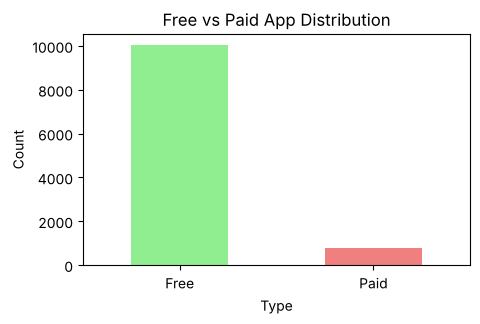

In [9]:
# Visualize the distribution of the 'Type' variable (Free vs Paid)

print(df[df['Type'].isin(['Free', 'Paid'])]['Type'].value_counts())

plt.figure(figsize=(5, 3))
df[df['Type'].isin(['Free', 'Paid'])]['Type'].value_counts().plot(kind='bar', color=['lightgreen', 'lightcoral'])
plt.title('Free vs Paid App Distribution')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

Category
FAMILY                 1972
GAME                   1144
TOOLS                   843
MEDICAL                 463
BUSINESS                460
PRODUCTIVITY            424
PERSONALIZATION         392
COMMUNICATION           387
SPORTS                  384
LIFESTYLE               382
FINANCE                 366
HEALTH_AND_FITNESS      341
PHOTOGRAPHY             335
SOCIAL                  295
NEWS_AND_MAGAZINES      283
SHOPPING                260
TRAVEL_AND_LOCAL        258
DATING                  234
BOOKS_AND_REFERENCE     231
VIDEO_PLAYERS           175
EDUCATION               156
ENTERTAINMENT           149
MAPS_AND_NAVIGATION     137
FOOD_AND_DRINK          127
HOUSE_AND_HOME           88
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
1.9                       1
Name: count, dtype: int64


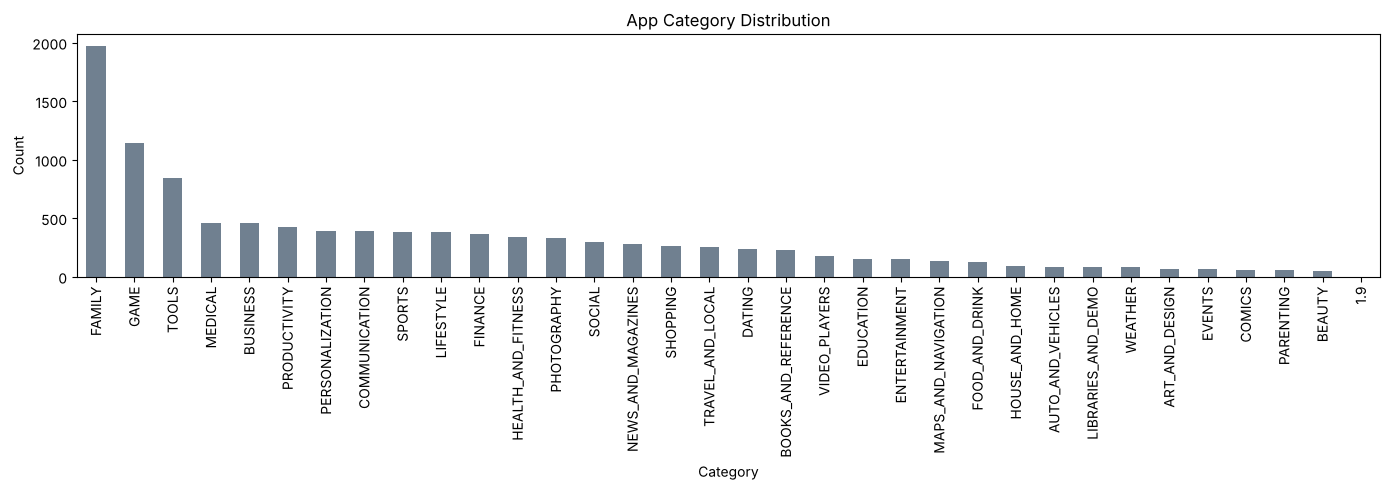

In [10]:
# Visualize the distribution of 'Category' variable

print(df['Category'].value_counts())

plt.figure(figsize=(14, 5))
df['Category'].value_counts().plot(kind='bar', color='slategrey')
plt.title('App Category Distribution')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Unrated               2
Name: count, dtype: int64


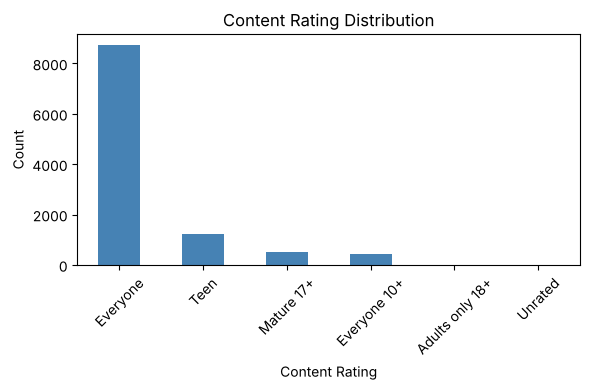

In [11]:
# Visualize the distribution of 'Content Rating' variable

print(df['Content Rating'].value_counts())

plt.figure(figsize=(6, 4))
df['Content Rating'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Content Rating Distribution')
plt.xlabel('Content Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

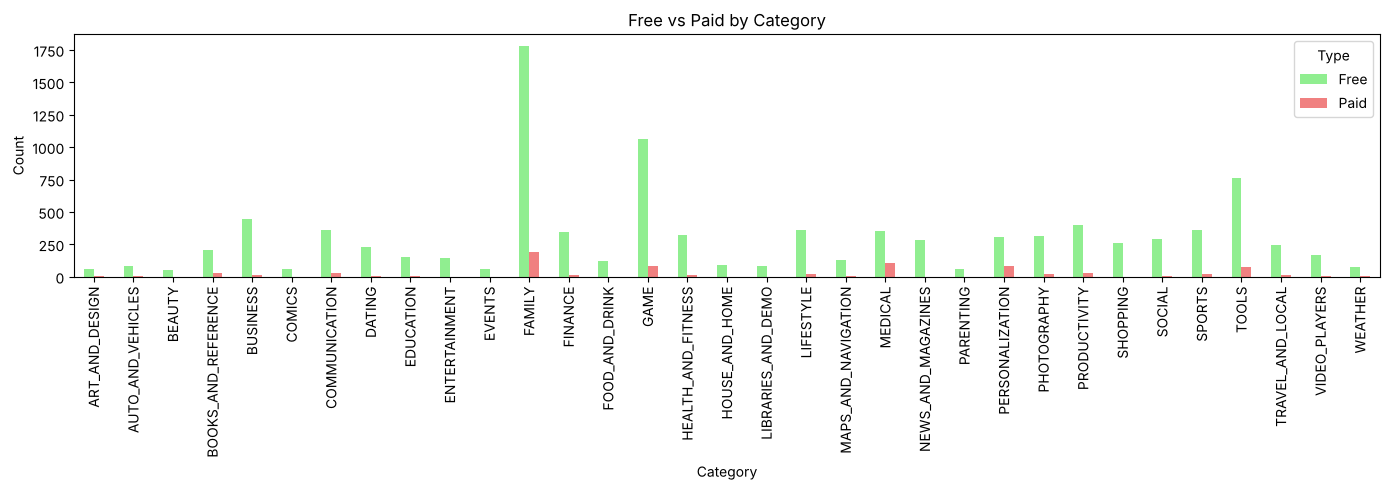

In [12]:
# Visualize the relationship between 'Category' and 'Type' (Free vs Paid)

df_valid_type = df[df['Type'].isin(['Free', 'Paid'])]

plt.figure(figsize=(14, 5))
pd.crosstab(df_valid_type['Category'], df_valid_type['Type']).plot(kind='bar', color=['lightgreen', 'lightcoral'], figsize=(14, 5))
plt.title('Free vs Paid by Category')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

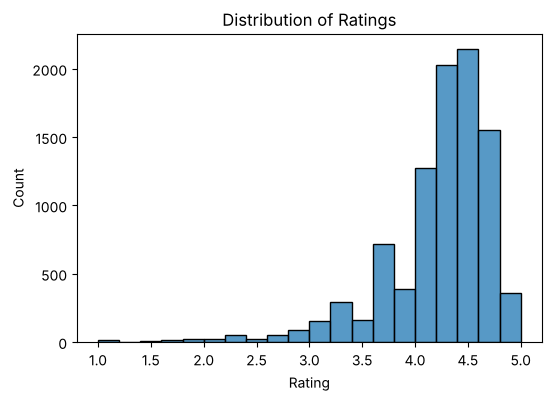

In [13]:
# Visualize the distribution of the 'Rating' variable

df_rated = df[pd.to_numeric(df['Rating'], errors='coerce').between(0, 5)].copy()
df_rated['Rating'] = pd.to_numeric(df_rated['Rating'])

plt.figure(figsize=(6, 4))
sns.histplot(df_rated['Rating'], bins=20)
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

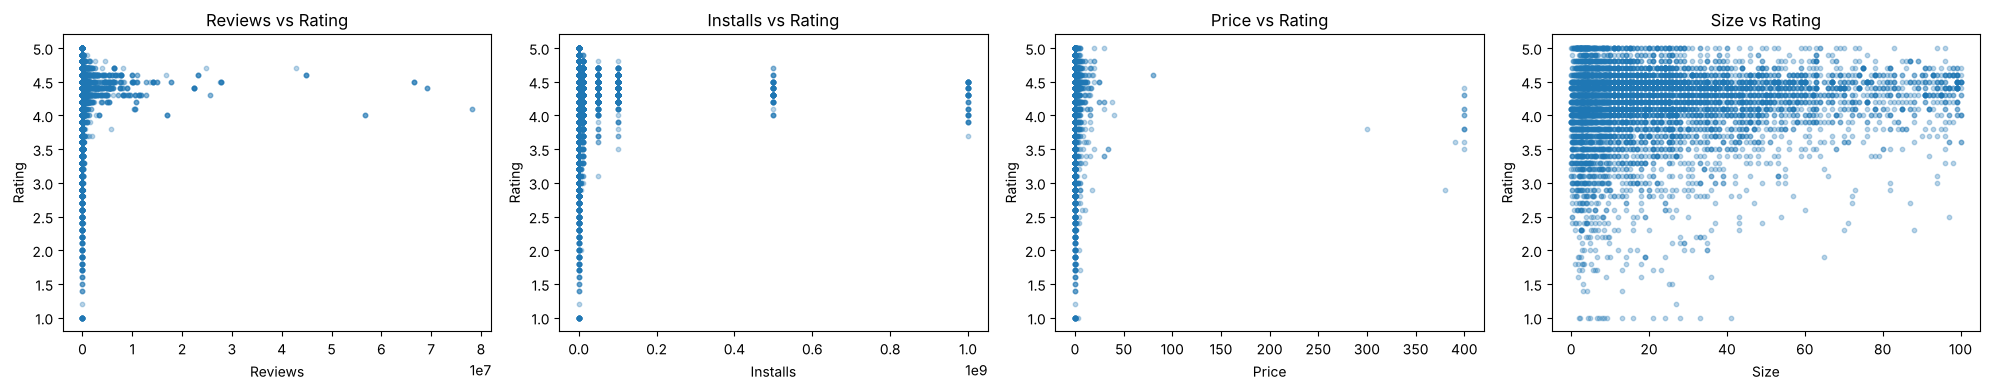

In [14]:
# scatter plots — numeric features vs rating

df_plot = df.copy()
df_plot['Rating']   = pd.to_numeric(df_plot['Rating'],   errors='coerce')
df_plot['Reviews']  = pd.to_numeric(df_plot['Reviews'],  errors='coerce')
df_plot['Installs'] = df_plot['Installs'].astype(str).str.replace('[+,]', '', regex=True)
df_plot['Installs'] = pd.to_numeric(df_plot['Installs'], errors='coerce')
df_plot['Price']    = df_plot['Price'].astype(str).str.replace('$', '', regex=False)
df_plot['Price']    = pd.to_numeric(df_plot['Price'],    errors='coerce')
df_plot['Size']     = df_plot['Size'].apply(
    lambda x: float(str(x)[:-1]) if str(x).endswith('M')
    else (float(str(x)[:-1])/1024 if str(x).endswith('k') else np.nan))
df_plot = df_plot[df_plot['Rating'].between(0, 5)]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['Reviews', 'Installs', 'Price', 'Size']):
    ax.scatter(df_plot[col], df_plot['Rating'], alpha=0.3, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel('Rating')
    ax.set_title(f'{col} vs Rating')
plt.tight_layout()
plt.show()

            Rating   Reviews  Installs     Price      Size
Rating    1.000000  0.068141  0.051355 -0.021903  0.083737
Reviews   0.068141  1.000000  0.641612 -0.009820  0.240413
Installs  0.051355  0.641612  1.000000 -0.011890  0.162759
Price    -0.021903 -0.009820 -0.011890  1.000000 -0.026242
Size      0.083737  0.240413  0.162759 -0.026242  1.000000


<Figure size 800x600 with 0 Axes>

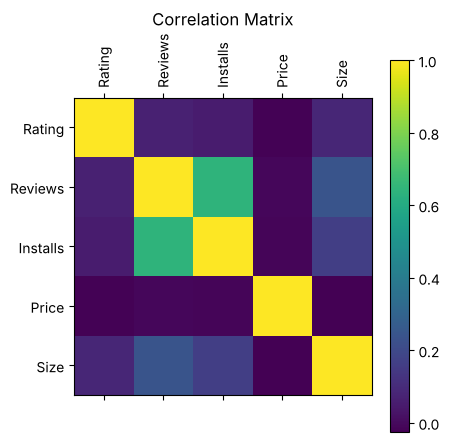

In [15]:
# Correlation matrix plot
plt.figure(figsize=(8, 6))
correlation_matrix = df_plot[['Rating', 'Reviews', 'Installs', 'Price', 'Size']].corr(numeric_only=True)
print(correlation_matrix)
plt.matshow(correlation_matrix)
plt.title('Correlation Matrix')
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.colorbar()
plt.show()

Recommended
0    7449
1    1917
Name: count, dtype: int64


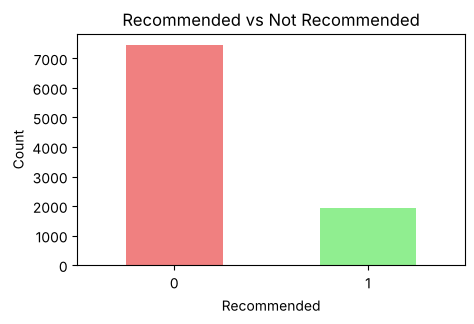

In [16]:
# Visualize Recommended vs Not Recommended (Task 2 target)

df_plot['Recommended'] = (df_plot['Rating'] > 4.5).astype(int)
print(df_plot['Recommended'].value_counts())

plt.figure(figsize=(5, 3))
df_plot['Recommended'].value_counts().plot(kind='bar', color=['lightcoral', 'lightgreen'])
plt.title('Recommended vs Not Recommended')
plt.xlabel('Recommended')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

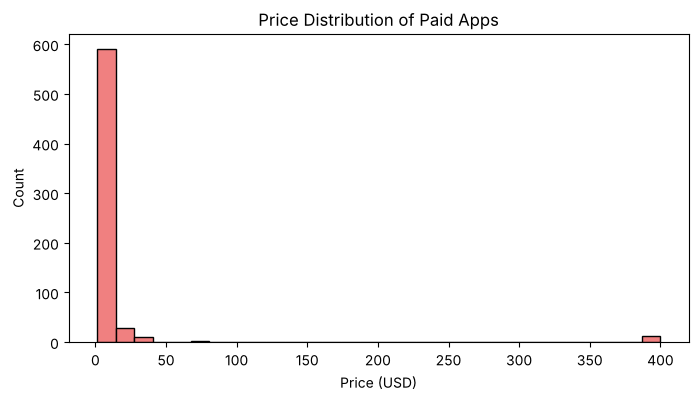

In [17]:
# price distribution for paid apps

paid_plot = df_plot[df_plot['Price'] > 0]
plt.figure(figsize=(8, 4))
plt.hist(paid_plot['Price'], bins=30, edgecolor='black', color='lightcoral')
plt.title('Price Distribution of Paid Apps')
plt.xlabel('Price (USD)')
plt.ylabel('Count')
plt.show()

# Data Preprocessing

In [18]:
#drop redundant features/columns
drop_cols = [c for c in ['Unnamed: 0', 'App', 'Last Updated', 'Current Ver', 'Android Ver'] if c in df.columns]
df = df.drop(drop_cols, axis=1)
df

,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design
1,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play
2,ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design
3,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design
4,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity
...,...,...,...,...,...,...,...,...,...
10836,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education
10837,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education
10838,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical
10839,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference


In [19]:
#drop rows with invalid Type values (keep only Free and Paid)
df = df[df['Type'].isin(['Free', 'Paid'])]
df

,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design
1,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play
2,ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design
3,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design
4,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity
...,...,...,...,...,...,...,...,...,...
10836,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education
10837,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education
10838,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical
10839,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference


In [20]:
#drop duplicates
df = df.drop_duplicates()
df

,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres
0,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design
1,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play
2,ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design
3,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design
4,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity
...,...,...,...,...,...,...,...,...,...
10836,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education
10837,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education
10838,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical
10839,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference


In [21]:
# clean the 'Price' column — remove '$' sign and convert to float
df['Price'] = df['Price'].astype(str).str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'], errors='coerce').fillna(0)
df['Price']

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
10836    0.0
10837    0.0
10838    0.0
10839    0.0
10840    0.0
Name: Price, Length: 10300, dtype: float64

In [22]:
# clean the 'Installs' column — remove '+' and ',' then convert to float
df['Installs'] = df['Installs'].astype(str).str.replace('[+,]', '', regex=True)
df['Installs'] = pd.to_numeric(df['Installs'], errors='coerce')
df['Installs']

0           10000
1          500000
2         5000000
3        50000000
4          100000
           ...   
10836        5000
10837         100
10838        1000
10839        1000
10840    10000000
Name: Installs, Length: 10300, dtype: int64

In [23]:
# clean the 'Size' column — convert MB and kB values, set 'Varies with device' to NaN
def clean_size(s):
    s = str(s)
    if s.endswith('M'):  return float(s[:-1])
    if s.endswith('k'):  return float(s[:-1]) / 1024
    return np.nan

df['Size'] = df['Size'].apply(clean_size)
df['Size']

0        19.0
1        14.0
2         8.7
3        25.0
4         2.8
         ... 
10836    53.0
10837     3.6
10838     9.5
10839     NaN
10840    19.0
Name: Size, Length: 10300, dtype: float64

In [24]:
df['Rating']  = pd.to_numeric(df['Rating'],  errors='coerce')
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

# fill missing values with median
df['Rating']   = df['Rating'].fillna(df['Rating'].median())
df['Size']     = df['Size'].fillna(df['Size'].median())
df['Reviews']  = df['Reviews'].fillna(df['Reviews'].median())
df['Installs'] = df['Installs'].fillna(df['Installs'].median())

# fill missing categorical values with mode
df['Category']       = df['Category'].fillna(df['Category'].mode()[0])
df['Content Rating'] = df['Content Rating'].fillna(df['Content Rating'].mode()[0])
df['Genres']         = df['Genres'].fillna(df['Genres'].mode()[0])

In [25]:
df.shape

(10300, 9)

In [26]:
df.isnull().sum()

Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
dtype: int64

In [27]:
#converting categorical variables to numerical (one-hot encoding)
df = pd.get_dummies(df, columns=['Category', 'Content Rating', 'Genres'])
df

,Rating,Reviews,Size,Installs,Type,Price,Category_ART_AND_DESIGN,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,...,Genres_Tools;Education,Genres_Travel & Local,Genres_Travel & Local;Action & Adventure,Genres_Trivia,Genres_Trivia;Education,Genres_Video Players & Editors,Genres_Video Players & Editors;Creativity,Genres_Video Players & Editors;Music & Video,Genres_Weather,Genres_Word
0,4.1,159,19.0,10000,Free,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,3.9,967,14.0,500000,Free,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,4.7,87510,8.7,5000000,Free,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4.5,215644,25.0,50000000,Free,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,4.3,967,2.8,100000,Free,0.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,4.5,38,53.0,5000,Free,0.0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10837,5.0,4,3.6,100,Free,0.0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10838,4.3,3,9.5,1000,Free,0.0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10839,4.5,114,13.0,1000,Free,0.0,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [28]:
df.shape

(10300, 164)

# Implementing Free/Paid Classification Using Scikit-learn Library

In [29]:
# encode target: Free = 0, Paid = 1
df['Is_Paid'] = (df['Type'] == 'Paid').astype(int)
print(df['Is_Paid'].value_counts())

Is_Paid
0    9536
1     764
Name: count, dtype: int64


In [30]:
# Split the data into 80-20 train-test split
# Reviews, Installs and Rating excluded — post-launch features not available at release time

feature_cols = ['Size', 'Price'] + \
               [c for c in df.columns if c.startswith('Category_') or c.startswith('Content Rating_') or c.startswith('Genres_')]

X = df[feature_cols]
y = df['Is_Paid']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8240, 160)
X_test shape: (2060, 160)
y_train shape: (8240,)
y_test shape: (2060,)


In [31]:
# Implementing Logistic Regression Classifier
lr_clf = LogisticRegression(max_iter=1000)
lr_clf.fit(X_train, y_train)

y_pred_lr = lr_clf.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=['Free', 'Paid']))

Logistic Regression Accuracy: 1.0
              precision    recall  f1-score   support

        Free       1.00      1.00      1.00      1914
        Paid       1.00      1.00      1.00       146

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [32]:
# Implementing Decision Tree Classifier
dt_clf = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=42)
dt_clf.fit(X_train, y_train)

y_pred_dt = dt_clf.predict(X_test)

print("Decision Tree Classifier Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt, target_names=['Free', 'Paid']))

Decision Tree Classifier Accuracy: 1.0
              precision    recall  f1-score   support

        Free       1.00      1.00      1.00      1914
        Paid       1.00      1.00      1.00       146

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [33]:
# Implementing Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)

print("Random Forest Classifier Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=['Free', 'Paid']))

Random Forest Classifier Accuracy: 1.0
              precision    recall  f1-score   support

        Free       1.00      1.00      1.00      1914
        Paid       1.00      1.00      1.00       146

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [34]:
# Implementing XGBoost Classifier
xgb_clf = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                         eval_metric='logloss', random_state=42)
xgb_clf.fit(X_train, y_train)

y_pred_xgb = xgb_clf.predict(X_test)

print("XGBoost Classifier Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb, target_names=['Free', 'Paid']))

XGBoost Classifier Accuracy: 1.0
              precision    recall  f1-score   support

        Free       1.00      1.00      1.00      1914
        Paid       1.00      1.00      1.00       146

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [35]:
# Implementing KNN Classifier
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train, y_train)

y_pred_knn = knn_clf.predict(X_test)

print("KNN Classifier Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn, target_names=['Free', 'Paid']))

KNN Classifier Accuracy: 0.9849514563106796
              precision    recall  f1-score   support

        Free       0.98      1.00      0.99      1914
        Paid       1.00      0.79      0.88       146

    accuracy                           0.98      2060
   macro avg       0.99      0.89      0.94      2060
weighted avg       0.99      0.98      0.98      2060



In [36]:
# check prediction output — Free stays as is, Paid goes to price prediction
for i in range(10):
    pred = y_pred_xgb[i]
    if pred == 0:
        print(f"App {i+1}: It's Free")
    else:
        print(f"App {i+1}: It's Paid — Price will be predicted by the regression model")

App 1: It's Free
App 2: It's Free
App 3: It's Free
App 4: It's Free
App 5: It's Free
App 6: It's Free
App 7: It's Free
App 8: It's Free
App 9: It's Free
App 10: It's Free


In [37]:
# Implementing Voting Classifier
voting_clf = VotingClassifier(estimators=[
    ('lr', lr_clf),
    ('dt', dt_clf),
    ('rf', rf_clf),
    ('xgb', xgb_clf),
    ('knn', knn_clf)
], voting='hard')
voting_clf.fit(X_train, y_train)

y_pred_voting = voting_clf.predict(X_test)

print("Voting Classifier Accuracy:", accuracy_score(y_test, y_pred_voting))
print(classification_report(y_test, y_pred_voting, target_names=['Free', 'Paid']))

Voting Classifier Accuracy: 1.0
              precision    recall  f1-score   support

        Free       1.00      1.00      1.00      1914
        Paid       1.00      1.00      1.00       146

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [38]:
# model comparison for Task 1a
task1a_results = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'KNN', 'Voting Classifier'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_voting)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, average='weighted'),
        precision_score(y_test, y_pred_dt, average='weighted'),
        precision_score(y_test, y_pred_rf, average='weighted'),
        precision_score(y_test, y_pred_xgb, average='weighted'),
        precision_score(y_test, y_pred_knn, average='weighted'),
        precision_score(y_test, y_pred_voting, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, average='weighted'),
        recall_score(y_test, y_pred_dt, average='weighted'),
        recall_score(y_test, y_pred_rf, average='weighted'),
        recall_score(y_test, y_pred_xgb, average='weighted'),
        recall_score(y_test, y_pred_knn, average='weighted'),
        recall_score(y_test, y_pred_voting, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, average='weighted'),
        f1_score(y_test, y_pred_dt, average='weighted'),
        f1_score(y_test, y_pred_rf, average='weighted'),
        f1_score(y_test, y_pred_xgb, average='weighted'),
        f1_score(y_test, y_pred_knn, average='weighted'),
        f1_score(y_test, y_pred_voting, average='weighted')
    ]
}

task1a_df = pd.DataFrame(task1a_results).set_index('Model').round(4)
print("Task 1a — Free/Paid Classification Results")
print(task1a_df)

Task 1a — Free/Paid Classification Results
                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression     1.000     1.0000   1.000    1.0000
Decision Tree           1.000     1.0000   1.000    1.0000
Random Forest           1.000     1.0000   1.000    1.0000
XGBoost                 1.000     1.0000   1.000    1.0000
KNN                     0.985     0.9852   0.985    0.9841
Voting Classifier       1.000     1.0000   1.000    1.0000


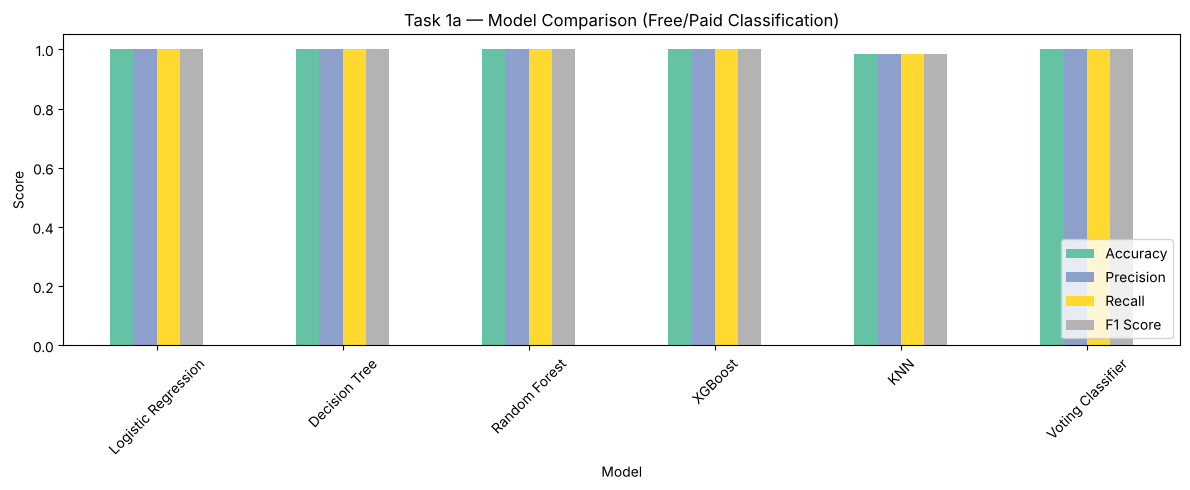

In [39]:
task1a_df.plot(kind='bar', figsize=(12, 5), colormap='Set2')
plt.title('Task 1a — Model Comparison (Free/Paid Classification)')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

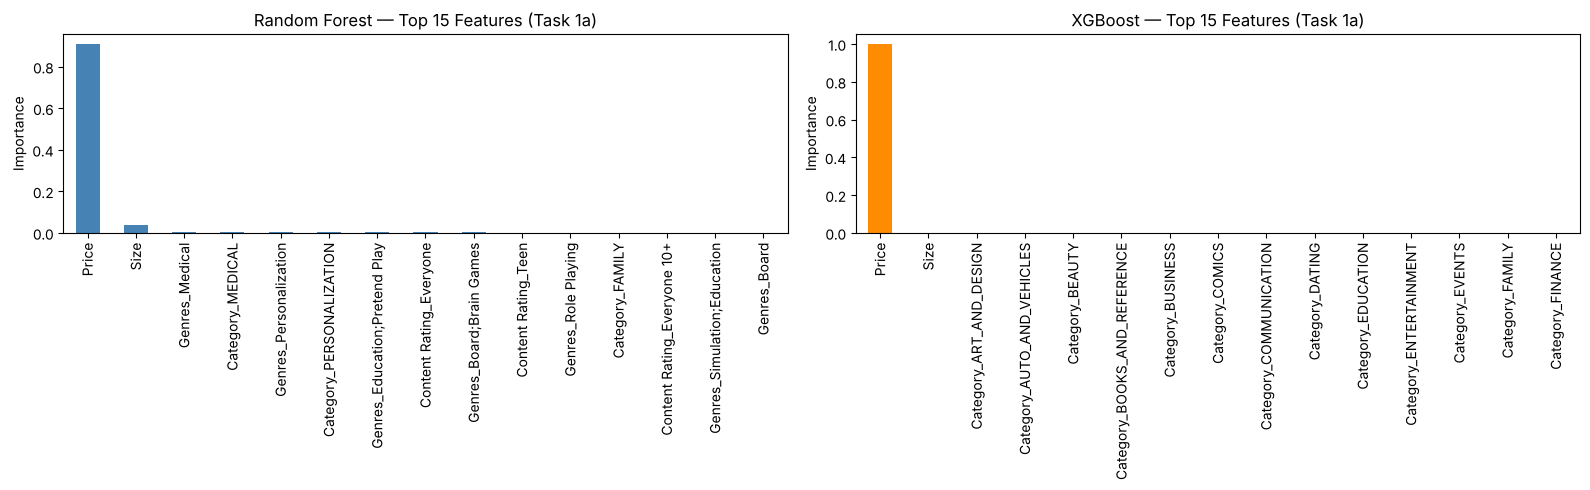

In [40]:
# feature importance — Random Forest and XGBoost for Task 1a
rf_imp = pd.Series(rf_clf.feature_importances_, index=feature_cols).sort_values(ascending=False)[:15]
xgb_imp = pd.Series(xgb_clf.feature_importances_, index=feature_cols).sort_values(ascending=False)[:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rf_imp.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Random Forest — Top 15 Features (Task 1a)')
axes[0].set_ylabel('Importance')
axes[0].tick_params(axis='x', rotation=90)

xgb_imp.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('XGBoost — Top 15 Features (Task 1a)')
axes[1].set_ylabel('Importance')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [41]:
# hard vs soft voting comparison for Task 1a
voting_soft_clf = VotingClassifier(estimators=[
    ('lr', lr_clf),
    ('dt', dt_clf),
    ('rf', rf_clf),
    ('xgb', xgb_clf),
    ('knn', knn_clf)
], voting='soft')
voting_soft_clf.fit(X_train, y_train)
y_pred_soft = voting_soft_clf.predict(X_test)

print("Hard Voting Accuracy:", accuracy_score(y_test, y_pred_voting))
print("Soft Voting Accuracy:", accuracy_score(y_test, y_pred_soft))

Hard Voting Accuracy: 1.0
Soft Voting Accuracy: 1.0


# Price Prediction for Paid Apps

In [42]:
# filter only paid apps
df_paid = df[df['Is_Paid'] == 1].copy()
print("Number of paid apps:", len(df_paid))
print()
print(df_paid['Price'].describe())

Number of paid apps: 764

count    764.000000
mean      13.972526
std       58.443340
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64


In [43]:
# same feature set as Task 1a — Reviews and Installs excluded
X_reg = df_paid[feature_cols]
y_reg = df_paid['Price']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

print("X_train shape:", X_train_reg.shape)
print("X_test shape:", X_test_reg.shape)

X_train shape: (611, 160)
X_test shape: (153, 160)


In [44]:
# Implementing Decision Tree Regressor for price prediction
dt_reg = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_reg.fit(X_train_reg, y_train_reg)

y_pred_dt_reg = dt_reg.predict(X_test_reg)

print("Decision Tree Regressor — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_dt_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_dt_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_dt_reg):.4f}")

Decision Tree Regressor — Price Prediction
MAE:  0.0685
RMSE: 0.4404
R2:   0.9999


In [45]:
# Implementing Linear Regression for price prediction
lr_reg = LinearRegression()
lr_reg.fit(X_train_reg, y_train_reg)

y_pred_lr_reg = lr_reg.predict(X_test_reg)

print("Linear Regression — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_lr_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_lr_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_lr_reg):.4f}")

Linear Regression — Price Prediction
MAE:  0.0000
RMSE: 0.0000
R2:   1.0000


In [46]:
# Implementing Random Forest Regressor for price prediction
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train_reg, y_train_reg)

y_pred_reg = rf_reg.predict(X_test_reg)

print("Random Forest Regressor — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_reg):.4f}")

Random Forest Regressor — Price Prediction
MAE:  0.0315
RMSE: 0.1779
R2:   1.0000


In [47]:
# Implementing XGBoost Regressor for price prediction
xgb_reg = XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42)
xgb_reg.fit(X_train_reg, y_train_reg)

y_pred_xgb_reg = xgb_reg.predict(X_test_reg)

print("XGBoost Regressor — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_xgb_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_xgb_reg):.4f}")

XGBoost Regressor — Price Prediction
MAE:  0.0459
RMSE: 0.4111
R2:   0.9999


In [48]:
# Implementing KNN Regressor for price prediction
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_reg, y_train_reg)

y_pred_knn_reg = knn_reg.predict(X_test_reg)

print("KNN Regressor — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_knn_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_knn_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_knn_reg):.4f}")

KNN Regressor — Price Prediction
MAE:  0.5873
RMSE: 1.1935
R2:   0.9995


In [49]:
# Implementing Voting Regressor for price prediction
voting_reg = VotingRegressor(estimators=[
    ('dt', dt_reg),
    ('lr', lr_reg),
    ('rf', rf_reg),
    ('xgb', xgb_reg),
    ('knn', knn_reg)
])
voting_reg.fit(X_train_reg, y_train_reg)

y_pred_voting_reg = voting_reg.predict(X_test_reg)

print("Voting Regressor — Price Prediction")
print(f"MAE:  {mean_absolute_error(y_test_reg, y_pred_voting_reg):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_reg, y_pred_voting_reg)):.4f}")
print(f"R2:   {r2_score(y_test_reg, y_pred_voting_reg):.4f}")

Voting Regressor — Price Prediction
MAE:  0.1371
RMSE: 0.3427
R2:   1.0000


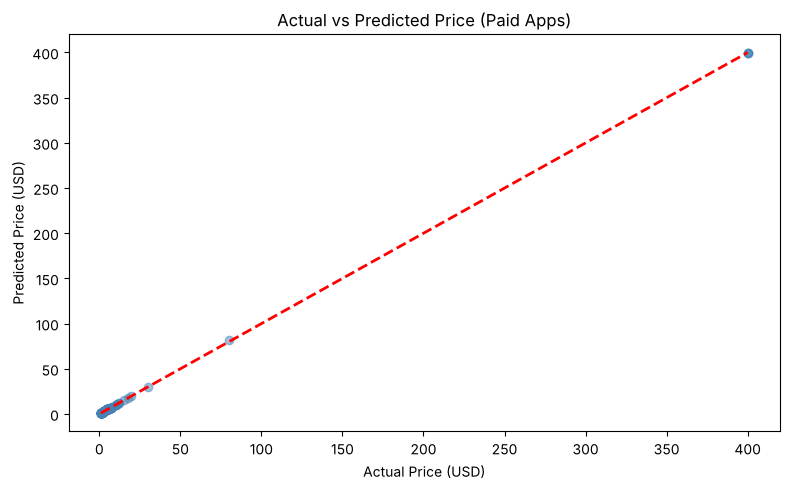

In [50]:
# actual vs predicted price (Random Forest)
plt.figure(figsize=(8, 5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.5, color='steelblue')
plt.plot([y_test_reg.min(), y_test_reg.max()],
         [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Price (Paid Apps)')
plt.xlabel('Actual Price (USD)')
plt.ylabel('Predicted Price (USD)')
plt.tight_layout()
plt.show()

In [51]:
# model comparison for Task 1b
task1b_results = {
    'Model': ['Decision Tree', 'Linear Regression', 'Random Forest', 'XGBoost', 'KNN', 'Voting Regressor'],
    'MAE': [
        mean_absolute_error(y_test_reg, y_pred_dt_reg),
        mean_absolute_error(y_test_reg, y_pred_lr_reg),
        mean_absolute_error(y_test_reg, y_pred_reg),
        mean_absolute_error(y_test_reg, y_pred_xgb_reg),
        mean_absolute_error(y_test_reg, y_pred_knn_reg),
        mean_absolute_error(y_test_reg, y_pred_voting_reg)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test_reg, y_pred_dt_reg)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_lr_reg)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_xgb_reg)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_knn_reg)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_voting_reg))
    ],
    'R2': [
        r2_score(y_test_reg, y_pred_dt_reg),
        r2_score(y_test_reg, y_pred_lr_reg),
        r2_score(y_test_reg, y_pred_reg),
        r2_score(y_test_reg, y_pred_xgb_reg),
        r2_score(y_test_reg, y_pred_knn_reg),
        r2_score(y_test_reg, y_pred_voting_reg)
    ]
}

task1b_df = pd.DataFrame(task1b_results).set_index('Model').round(4)
print("Task 1b — Price Prediction Results")
print(task1b_df)

Task 1b — Price Prediction Results
                      MAE    RMSE      R2
Model                                    
Decision Tree      0.0685  0.4404  0.9999
Linear Regression  0.0000  0.0000  1.0000
Random Forest      0.0315  0.1779  1.0000
XGBoost            0.0459  0.4111  0.9999
KNN                0.5873  1.1935  0.9995
Voting Regressor   0.1371  0.3427  1.0000


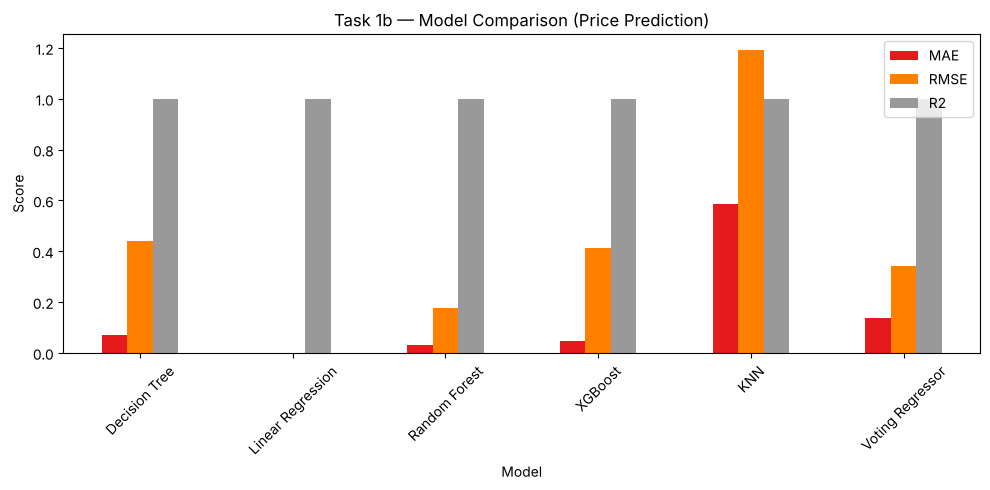

In [52]:
task1b_df.plot(kind='bar', figsize=(10, 5), colormap='Set1')
plt.title('Task 1b — Model Comparison (Price Prediction)')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

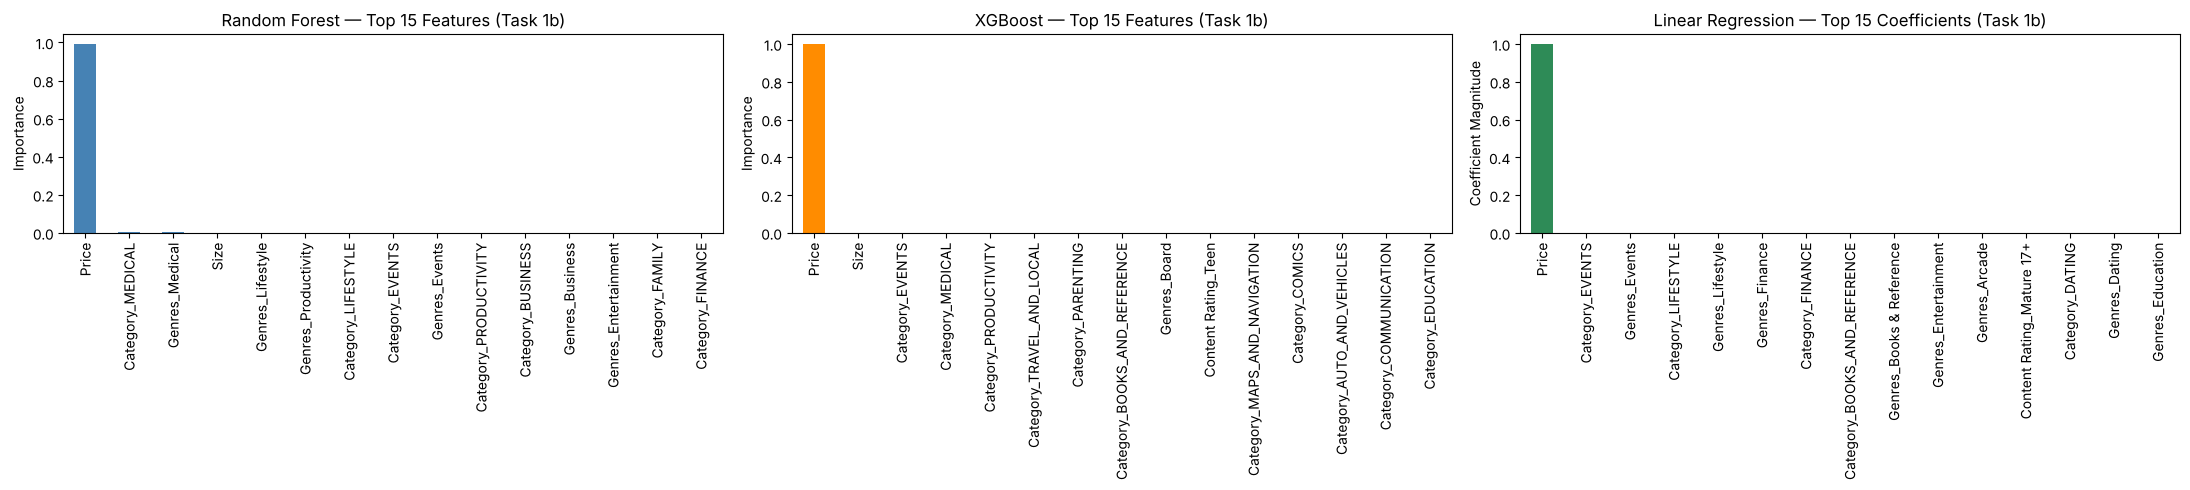

In [53]:
# feature importance — Random Forest and XGBoost for Task 1b
rf_imp_reg = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)[:15]
xgb_imp_reg = pd.Series(xgb_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)[:15]

# linear regression uses coefficients instead of feature_importances_
lr_coef = pd.Series(np.abs(lr_reg.coef_), index=feature_cols).sort_values(ascending=False)[:15]

fig, axes = plt.subplots(1, 3, figsize=(22, 5))
rf_imp_reg.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Random Forest — Top 15 Features (Task 1b)')
axes[0].set_ylabel('Importance')
axes[0].tick_params(axis='x', rotation=90)

xgb_imp_reg.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('XGBoost — Top 15 Features (Task 1b)')
axes[1].set_ylabel('Importance')
axes[1].tick_params(axis='x', rotation=90)

lr_coef.plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Linear Regression — Top 15 Coefficients (Task 1b)')
axes[2].set_ylabel('Coefficient Magnitude')
axes[2].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [54]:
# Full Task 1 pipeline: Free/Paid check -> if Paid, predict price
print("Sample predictions from Task 1 pipeline:\n")
sample_X = X_test.iloc[:10]

type_preds = xgb_clf.predict(sample_X)

for i, pred in enumerate(type_preds):
    if pred == 0:
        print(f"App {i+1}: It's Free")
    else:
        price_pred = rf_reg.predict(sample_X.iloc[[i]])[0]
        print(f"App {i+1}: It's Paid — Predicted Price: ${price_pred:.2f}")

Sample predictions from Task 1 pipeline:

App 1: It's Free
App 2: It's Free
App 3: It's Free
App 4: It's Free
App 5: It's Free
App 6: It's Free
App 7: It's Free
App 8: It's Free
App 9: It's Free
App 10: It's Free


# Implementing Rating Classification Using Scikit-learn Library

In [55]:
# create the Recommended target column
df['Recommended'] = (df['Rating'] > 4.5).astype(int)
print(df['Recommended'].value_counts())

Recommended
0    8462
1    1838
Name: count, dtype: int64


In [56]:
# Split the data into 80-20 train-test split
# Reviews and Installs excluded — post-launch features not available at release time

rating_feature_cols = ['Size', 'Price'] + \
                      [c for c in df.columns if c.startswith('Category_') or c.startswith('Content Rating_') or c.startswith('Genres_')]

X_r = df[rating_feature_cols]
y_r = df['Recommended']

X_r_train, X_r_test, y_r_train, y_r_test = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

print("X_train shape:", X_r_train.shape)
print("X_test shape:", X_r_test.shape)
print("y_train shape:", y_r_train.shape)
print("y_test shape:", y_r_test.shape)

X_train shape: (8240, 160)
X_test shape: (2060, 160)
y_train shape: (8240,)
y_test shape: (2060,)


In [57]:
# Implementing Logistic Regression Classifier
lr_rating = LogisticRegression(max_iter=1000)
lr_rating.fit(X_r_train, y_r_train)

y_pred_lr_r = lr_rating.predict(X_r_test)

print("Logistic Regression Accuracy:", accuracy_score(y_r_test, y_pred_lr_r))
print(classification_report(y_r_test, y_pred_lr_r, target_names=['Not Recommended', 'Recommended']))

Logistic Regression Accuracy: 0.8097087378640777
                 precision    recall  f1-score   support

Not Recommended       0.81      1.00      0.89      1668
    Recommended       0.00      0.00      0.00       392

       accuracy                           0.81      2060
      macro avg       0.40      0.50      0.45      2060
   weighted avg       0.66      0.81      0.72      2060



In [58]:
# Implementing Decision Tree Classifier
dt_rating = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=42)
dt_rating.fit(X_r_train, y_r_train)

y_pred_dt_r = dt_rating.predict(X_r_test)

print("Decision Tree Classifier Accuracy:", accuracy_score(y_r_test, y_pred_dt_r))
print(classification_report(y_r_test, y_pred_dt_r, target_names=['Not Recommended', 'Recommended']))

Decision Tree Classifier Accuracy: 0.8029126213592233
                 precision    recall  f1-score   support

Not Recommended       0.81      0.99      0.89      1668
    Recommended       0.29      0.03      0.05       392

       accuracy                           0.80      2060
      macro avg       0.55      0.51      0.47      2060
   weighted avg       0.71      0.80      0.73      2060



In [59]:
# Implementing Random Forest Classifier
rf_rating = RandomForestClassifier(n_estimators=100, random_state=42)
rf_rating.fit(X_r_train, y_r_train)

y_pred_rf_r = rf_rating.predict(X_r_test)

print("Random Forest Classifier Accuracy:", accuracy_score(y_r_test, y_pred_rf_r))
print(classification_report(y_r_test, y_pred_rf_r, target_names=['Not Recommended', 'Recommended']))

Random Forest Classifier Accuracy: 0.7762135922330097
                 precision    recall  f1-score   support

Not Recommended       0.83      0.91      0.87      1668
    Recommended       0.36      0.22      0.27       392

       accuracy                           0.78      2060
      macro avg       0.59      0.56      0.57      2060
   weighted avg       0.74      0.78      0.75      2060



In [60]:
# Implementing XGBoost Classifier
xgb_rating = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1,
                            eval_metric='logloss', random_state=42)
xgb_rating.fit(X_r_train, y_r_train)

y_pred_xgb_r = xgb_rating.predict(X_r_test)

print("XGBoost Classifier Accuracy:", accuracy_score(y_r_test, y_pred_xgb_r))
print(classification_report(y_r_test, y_pred_xgb_r, target_names=['Not Recommended', 'Recommended']))

XGBoost Classifier Accuracy: 0.8077669902912621
                 precision    recall  f1-score   support

Not Recommended       0.81      1.00      0.89      1668
    Recommended       0.33      0.01      0.02       392

       accuracy                           0.81      2060
      macro avg       0.57      0.50      0.46      2060
   weighted avg       0.72      0.81      0.73      2060



In [61]:
# Implementing KNN Classifier
knn_rating = KNeighborsClassifier(n_neighbors=5)
knn_rating.fit(X_r_train, y_r_train)

y_pred_knn_r = knn_rating.predict(X_r_test)

print("KNN Classifier Accuracy:", accuracy_score(y_r_test, y_pred_knn_r))
print(classification_report(y_r_test, y_pred_knn_r, target_names=['Not Recommended', 'Recommended']))

KNN Classifier Accuracy: 0.7970873786407767
                 precision    recall  f1-score   support

Not Recommended       0.82      0.95      0.88      1668
    Recommended       0.40      0.13      0.20       392

       accuracy                           0.80      2060
      macro avg       0.61      0.54      0.54      2060
   weighted avg       0.74      0.80      0.75      2060



In [62]:
# Implementing Voting Classifier
voting_rating = VotingClassifier(estimators=[
    ('lr', lr_rating),
    ('dt', dt_rating),
    ('rf', rf_rating),
    ('xgb', xgb_rating),
    ('knn', knn_rating)
], voting='hard')
voting_rating.fit(X_r_train, y_r_train)

y_pred_voting_r = voting_rating.predict(X_r_test)

print("Voting Classifier Accuracy:", accuracy_score(y_r_test, y_pred_voting_r))
print(classification_report(y_r_test, y_pred_voting_r, target_names=['Not Recommended', 'Recommended']))

Voting Classifier Accuracy: 0.8067961165048544
                 precision    recall  f1-score   support

Not Recommended       0.81      0.99      0.89      1668
    Recommended       0.36      0.02      0.04       392

       accuracy                           0.81      2060
      macro avg       0.59      0.51      0.47      2060
   weighted avg       0.73      0.81      0.73      2060



In [63]:
# model comparison for Task 2
task2_results = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'KNN', 'Voting Classifier'],
    'Accuracy': [
        accuracy_score(y_r_test, y_pred_lr_r),
        accuracy_score(y_r_test, y_pred_dt_r),
        accuracy_score(y_r_test, y_pred_rf_r),
        accuracy_score(y_r_test, y_pred_xgb_r),
        accuracy_score(y_r_test, y_pred_knn_r),
        accuracy_score(y_r_test, y_pred_voting_r)
    ],
    'Precision': [
        precision_score(y_r_test, y_pred_lr_r, average='weighted'),
        precision_score(y_r_test, y_pred_dt_r, average='weighted'),
        precision_score(y_r_test, y_pred_rf_r, average='weighted'),
        precision_score(y_r_test, y_pred_xgb_r, average='weighted'),
        precision_score(y_r_test, y_pred_knn_r, average='weighted'),
        precision_score(y_r_test, y_pred_voting_r, average='weighted')
    ],
    'Recall': [
        recall_score(y_r_test, y_pred_lr_r, average='weighted'),
        recall_score(y_r_test, y_pred_dt_r, average='weighted'),
        recall_score(y_r_test, y_pred_rf_r, average='weighted'),
        recall_score(y_r_test, y_pred_xgb_r, average='weighted'),
        recall_score(y_r_test, y_pred_knn_r, average='weighted'),
        recall_score(y_r_test, y_pred_voting_r, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_r_test, y_pred_lr_r, average='weighted'),
        f1_score(y_r_test, y_pred_dt_r, average='weighted'),
        f1_score(y_r_test, y_pred_rf_r, average='weighted'),
        f1_score(y_r_test, y_pred_xgb_r, average='weighted'),
        f1_score(y_r_test, y_pred_knn_r, average='weighted'),
        f1_score(y_r_test, y_pred_voting_r, average='weighted')
    ]
}

task2_df = pd.DataFrame(task2_results).set_index('Model').round(4)
print("Task 2 — Recommended Classification Results")
print(task2_df)

Task 2 — Recommended Classification Results
                     Accuracy  Precision  Recall  F1 Score
Model                                                     
Logistic Regression    0.8097     0.6556  0.8097    0.7246
Decision Tree          0.8029     0.7130  0.8029    0.7296
Random Forest          0.7762     0.7414  0.7762    0.7544
XGBoost                0.8078     0.7197  0.8078    0.7272
KNN                    0.7971     0.7426  0.7971    0.7530
Voting Classifier      0.8068     0.7263  0.8068    0.7301


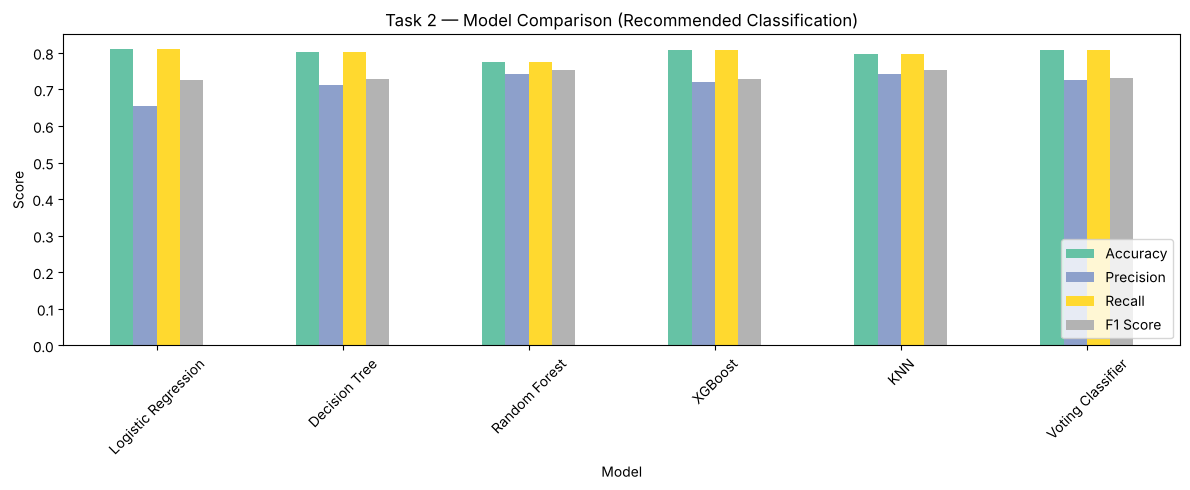

In [64]:
task2_df.plot(kind='bar', figsize=(12, 5), colormap='Set2')
plt.title('Task 2 — Model Comparison (Recommended Classification)')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

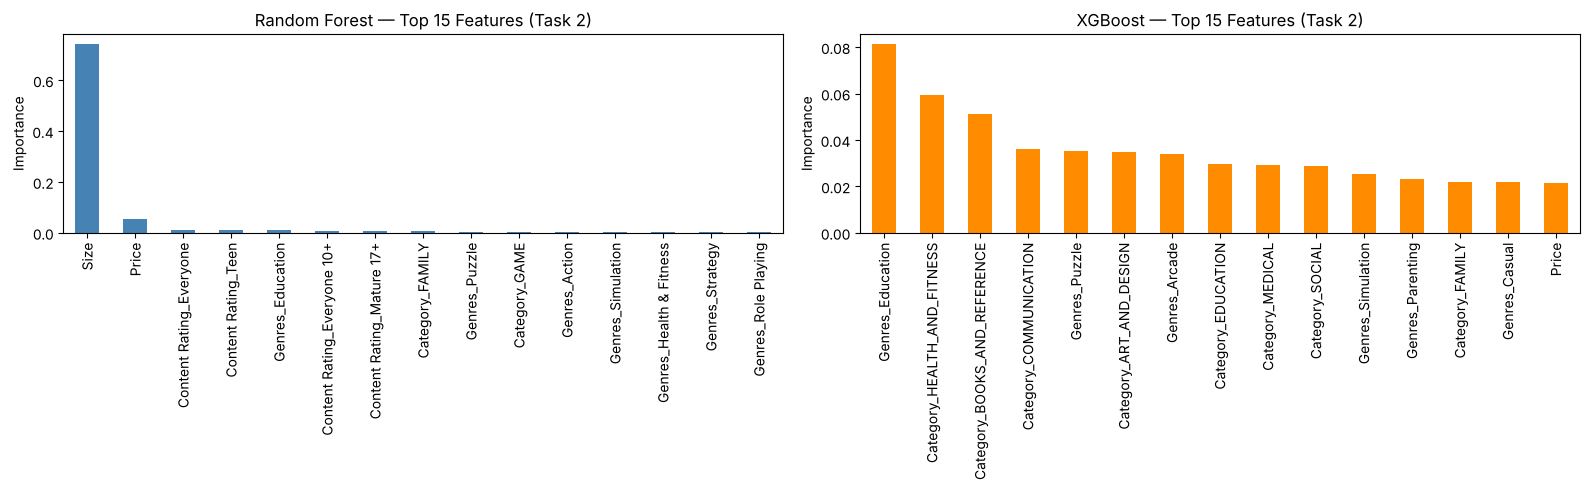

In [65]:
# feature importance — Random Forest and XGBoost for Task 2
rf_imp_r = pd.Series(rf_rating.feature_importances_, index=rating_feature_cols).sort_values(ascending=False)[:15]
xgb_imp_r = pd.Series(xgb_rating.feature_importances_, index=rating_feature_cols).sort_values(ascending=False)[:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
rf_imp_r.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Random Forest — Top 15 Features (Task 2)')
axes[0].set_ylabel('Importance')
axes[0].tick_params(axis='x', rotation=90)

xgb_imp_r.plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('XGBoost — Top 15 Features (Task 2)')
axes[1].set_ylabel('Importance')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

In [66]:
# hard vs soft voting comparison for Task 2
voting_soft_rating = VotingClassifier(estimators=[
    ('lr', lr_rating),
    ('dt', dt_rating),
    ('rf', rf_rating),
    ('xgb', xgb_rating),
    ('knn', knn_rating)
], voting='soft')
voting_soft_rating.fit(X_r_train, y_r_train)
y_pred_soft_r = voting_soft_rating.predict(X_r_test)

print("Hard Voting Accuracy:", accuracy_score(y_r_test, y_pred_voting_r))
print("Soft Voting Accuracy:", accuracy_score(y_r_test, y_pred_soft_r))

Hard Voting Accuracy: 0.8067961165048544
Soft Voting Accuracy: 0.8087378640776699
